# Auswertung Versuch 256 in Jupiter Notebook

### 1. Import der Daten und Python Bibliotheken

In [17]:
#Import
import matplotlib.pyplot as plt 
import numpy as np
from scipy.optimize import curve_fit
#alpha
Z_alpha = np.array([22, 26, 28, 29, 30, 40, 42, 47])
K_alpha = np.array([4.83, 6.43, 7.37, 7.95, 8.59, 15.84, 17.49, 21.90])
Delta_K_alpha = np.array([0.18, 0.21, 0.25, 0.23, 0.21, 0.18, 0.18, 0.18])
#beta
Z_beta = np.array([22, 26, 28, 29, 30, 40, 42, 47])
K_beta = np.array([5.08, 7.01, 8.04, 8.73, 9.46, 17.68, 19.56, 24.48])
Delta_K_beta = np.array([0.21, 0.23, 0.28, 0.27, 0.21, 0.19, 0.19, 0.19])
sqrt_K_beta = np.sqrt(K_beta)

### Fit Funktionen

In [23]:
# Fit K_alpha (n1=1, n2=2)
def fit_func_alpha(x, sqrt_Er, sig12):
    return sqrt_Er * (x - sig12) * np.sqrt(1/1**2 - 1/2**2)
# Fit K_beta (n1=1, n2=3)
def fit_func_beta(x, sqrt_Er, sig12):
    return sqrt_Er * (x - sig12) * np.sqrt(1/1**2 - 1/3**2)

### Code für $K_\alpha$ 

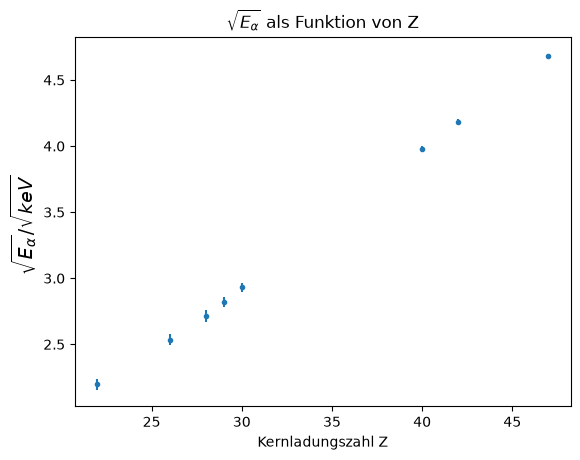

In [ ]:
# Fehlerberechnung
sqrt_K_alpha = np.sqrt(K_alpha)
Delta_sqrt_K_alpha = Delta_K_alpha / (2 * sqrt_K_alpha)
# sqrt(E_alpha) über Z Plot
plt.errorbar(Z_alpha, sqrt_K_alpha, Delta_sqrt_K_alpha, fmt=".") 
plt.xlabel('Kernladungszahl Z') 
plt.ylabel(r'$\sqrt{E_\alpha}/\sqrt{keV}$ ', fontsize=14) 
plt.title(r'$\sqrt{E_\alpha}$' + ' als Funktion von Z') 
plt.savefig("figures/K_alpha_vs_Z.pdf", format="pdf")

<>:10: SyntaxWarning: invalid escape sequence '\s'
<>:10: SyntaxWarning: invalid escape sequence '\s'
C:\Users\loren\AppData\Local\Temp\ipykernel_14788\3035469098.py:10: SyntaxWarning: invalid escape sequence '\s'
  plt.plot(Z_alpha, fit_func_alpha(Z_alpha, *(popt_alpha + fehler_alpha)),color="red",linestyle="--",label="1-$\sigma$ Fehler")


sqrt_Er= 0.11752077976183276 ,Standardfehler= 0.0011780286581863104
sig12= 0.9832261054446859 ,Standardfehler= 0.38374051817038246


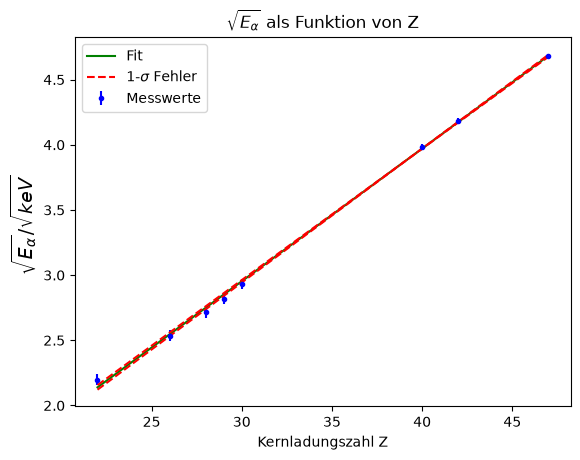

In [31]:
#Fit über nach sqrt(E_alpha) umgestelltes Moseley Gesetz

#fit Funktion
popt_alpha, pcov_alpha = curve_fit(fit_func_alpha, Z_alpha, sqrt_K_alpha, sigma=Delta_sqrt_K_alpha)
fehler_alpha = np.sqrt(np.diag(pcov_alpha))
#plot
plt.errorbar(Z_alpha, sqrt_K_alpha, Delta_sqrt_K_alpha, fmt=".", color = 'blue', label = 'Messwerte')
plt.title(r'$\sqrt{E_\alpha}$' + ' als Funktion von Z')
plt.plot(Z_alpha, fit_func_alpha(Z_alpha,*popt_alpha), color = 'green', label = 'Fit')
plt.plot(Z_alpha, fit_func_alpha(Z_alpha, *(popt_alpha + fehler_alpha)),color="red",linestyle="--",label="1-$\sigma$ Fehler")
plt.plot(Z_alpha, fit_func_alpha(Z_alpha, *(popt_alpha - fehler_alpha)),color="red",linestyle="--")
plt.xlabel('Kernladungszahl Z')
plt.ylabel(r'$\sqrt{E_\alpha}/\sqrt{keV}$ ', fontsize=14)
plt.legend(loc="upper left")
plt.savefig("figures/K_alpha_vs_Z_fit.pdf", format="pdf")
#fit Ergebnisse
print("sqrt_Er=",popt_alpha[0], ",Standardfehler=",np.sqrt(pcov_alpha[0][0])) 
print("sig12=",popt_alpha[1], ",Standardfehler=",np.sqrt(pcov_alpha[1][1]))

In [ ]:
#Berechnungen K_alpha

E_R = 1000 * popt_alpha[0]**2
Delta_E_R = 2000 * abs(popt_alpha[0]) * fehler_alpha[0]
print(f"Rydberg-Energie: ({E_R:.2f} pm  {np.ceil(Delta_E_R * 100) / 100:.2f}) eV")


Rydberg-Energie: (13.81 pm  0.28 eV


### Code für $K_\beta$

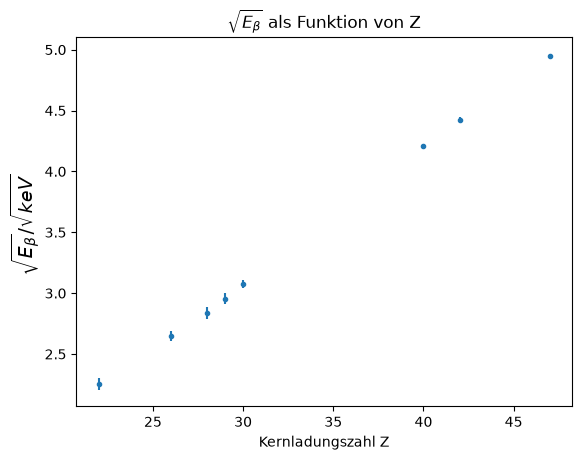

In [18]:
# Fehlerberechnung
sqrt_K_beta = np.sqrt(K_beta)
Delta_sqrt_K_beta = Delta_K_beta / (2 * sqrt_K_beta)
# sqrt(E_beta) über Z Plot
plt.errorbar(Z_beta, sqrt_K_beta, Delta_sqrt_K_beta, fmt=".") 
plt.xlabel('Kernladungszahl Z') 
plt.ylabel(r'$\sqrt{E_\beta}/\sqrt{keV}$ ', fontsize=14) 
plt.title(r'$\sqrt{E_\beta}$' + ' als Funktion von Z') 
plt.savefig("figures/K_beta_vs_Z.pdf", format="pdf")

<>:10: SyntaxWarning: invalid escape sequence '\s'
<>:10: SyntaxWarning: invalid escape sequence '\s'
C:\Users\loren\AppData\Local\Temp\ipykernel_14788\366637266.py:10: SyntaxWarning: invalid escape sequence '\s'
  plt.plot(Z_beta, fit_func_beta(Z_beta, *(popt_beta + fehler_beta)),color="red",linestyle="--",label="1-$\sigma$ Abweichung")


sqrt_Er= 0.11650115181219416 ,Standardfehler= 0.0009855601340209835
sig12= 1.8514225509629743 ,Standardfehler= 0.3197668212713639


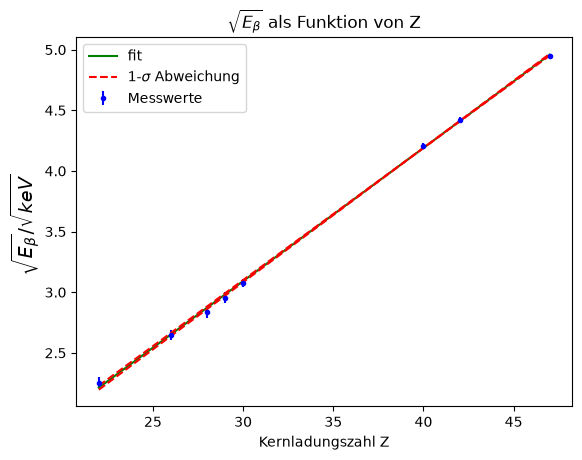

In [32]:
#Fit über nach sqrt(E_beta) umgestelltes Moseley Gesetz

#fit Funktion
popt_beta, pcov_beta = curve_fit(fit_func_beta, Z_beta, sqrt_K_beta, sigma=Delta_sqrt_K_beta)
fehler_beta = np.sqrt(np.diag(pcov_beta))
#plot
plt.errorbar(Z_beta, sqrt_K_beta, Delta_sqrt_K_beta, fmt=".", color = 'blue', label = 'Messwerte')
plt.title(r'$\sqrt{E_\beta}$' + ' als Funktion von Z')
plt.plot(Z_beta, fit_func_beta(Z_beta,*popt_beta), color = 'green', label = 'fit')
plt.plot(Z_beta, fit_func_beta(Z_beta, *(popt_beta + fehler_beta)),color="red",linestyle="--",label="1-$\sigma$ Abweichung")
plt.plot(Z_beta, fit_func_beta(Z_beta, *(popt_beta - fehler_beta)),color="red",linestyle="--")
plt.xlabel('Kernladungszahl Z')
plt.ylabel(r'$\sqrt{E_\beta}/\sqrt{keV}$ ', fontsize=14)
plt.legend(loc="upper left")
plt.savefig("figures/K_beta_vs_Z_fit.pdf", format="pdf")
#fit Ergebnisse
print("sqrt_Er=",popt_beta[0], ",Standardfehler=",np.sqrt(pcov_beta[0][0])) 
print("sig12=",popt_beta[1], ",Standardfehler=",np.sqrt(pcov_beta[1][1]))

In [26]:
#Berechnungen K_beta

E_R_beta = 1000 * popt_beta[0]**2
Delta_E_R_beta = 2000 * abs(popt_beta[0]) * fehler_beta[0]
print(f"Rydberg-Energie: ({E_R_beta:.2f} pm  {np.ceil(Delta_E_R_beta * 100) / 100:.2f}) eV")


Rydberg-Energie: (13.57 pm  0.23) eV
